In [10]:
# Import libraries and load the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("student-mat.csv", sep=";")

sns.set_theme(style="whitegrid")

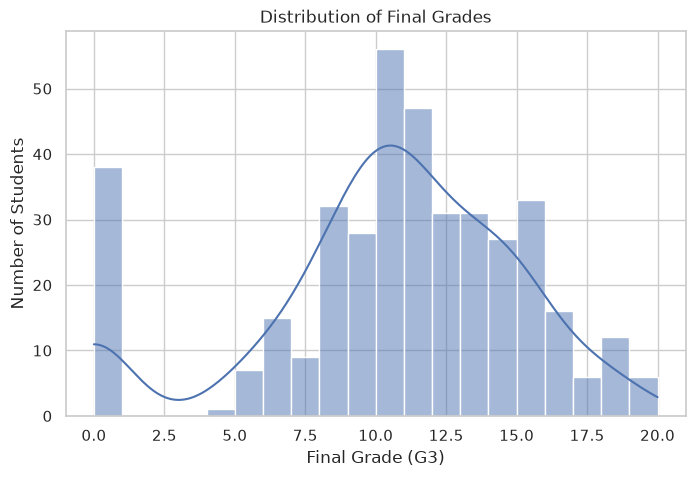

In [11]:
# Univariate analysis — examine individual variables

# Univariate analysis — examine individual variables

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="G3", bins=20, kde=True)

plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.show()

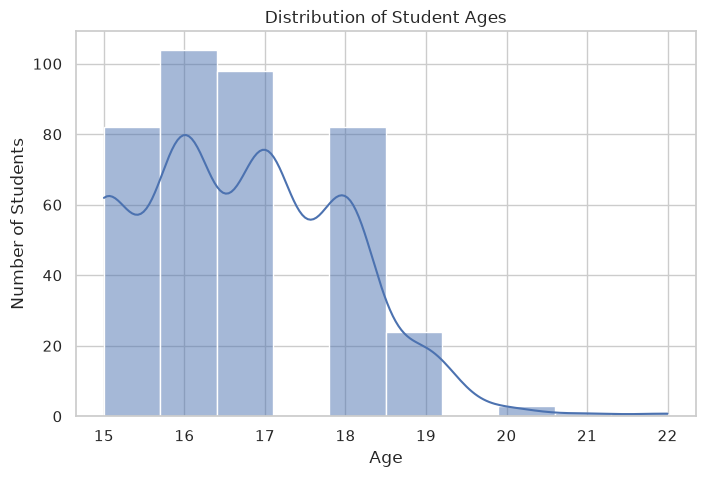

In [12]:
# Distribution of students' ages

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=10, kde=True)

plt.title("Distribution of Student Ages")
plt.xlabel("Age")
plt.ylabel("Number of Students")
plt.show()

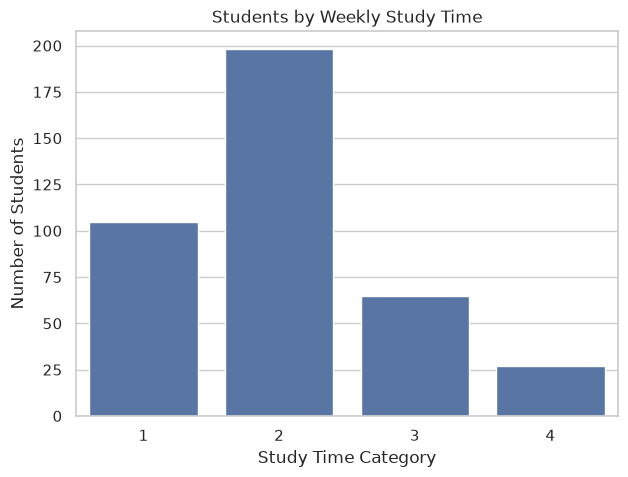

In [13]:
# Study time distribution

plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="studytime")

plt.title("Students by Weekly Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Number of Students")
plt.show()

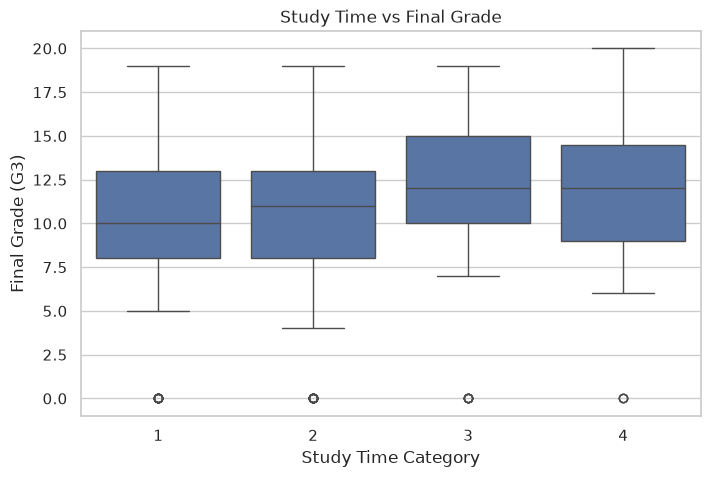

In [14]:
# Bivariate analysis — examine relationships
# Study time vs final grade

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="studytime", y="G3")

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade (G3)")
plt.show()

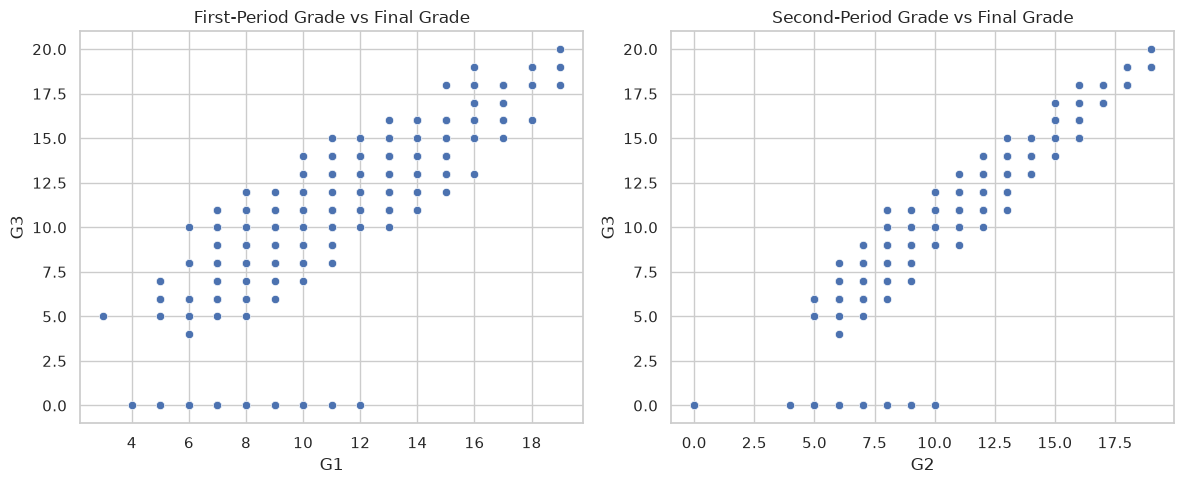

In [15]:
# Previous grades vs final grade

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(data=df, x="G1", y="G3", ax=axes[0])
axes[0].set_title("First-Period Grade vs Final Grade")

sns.scatterplot(data=df, x="G2", y="G3", ax=axes[1])
axes[1].set_title("Second-Period Grade vs Final Grade")

plt.tight_layout()
plt.show()

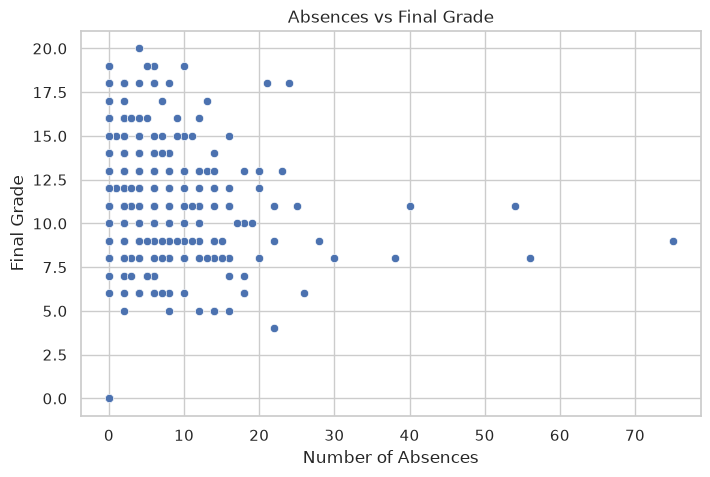

In [16]:
# Absences vs final grade

plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x="absences", y="G3")

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()

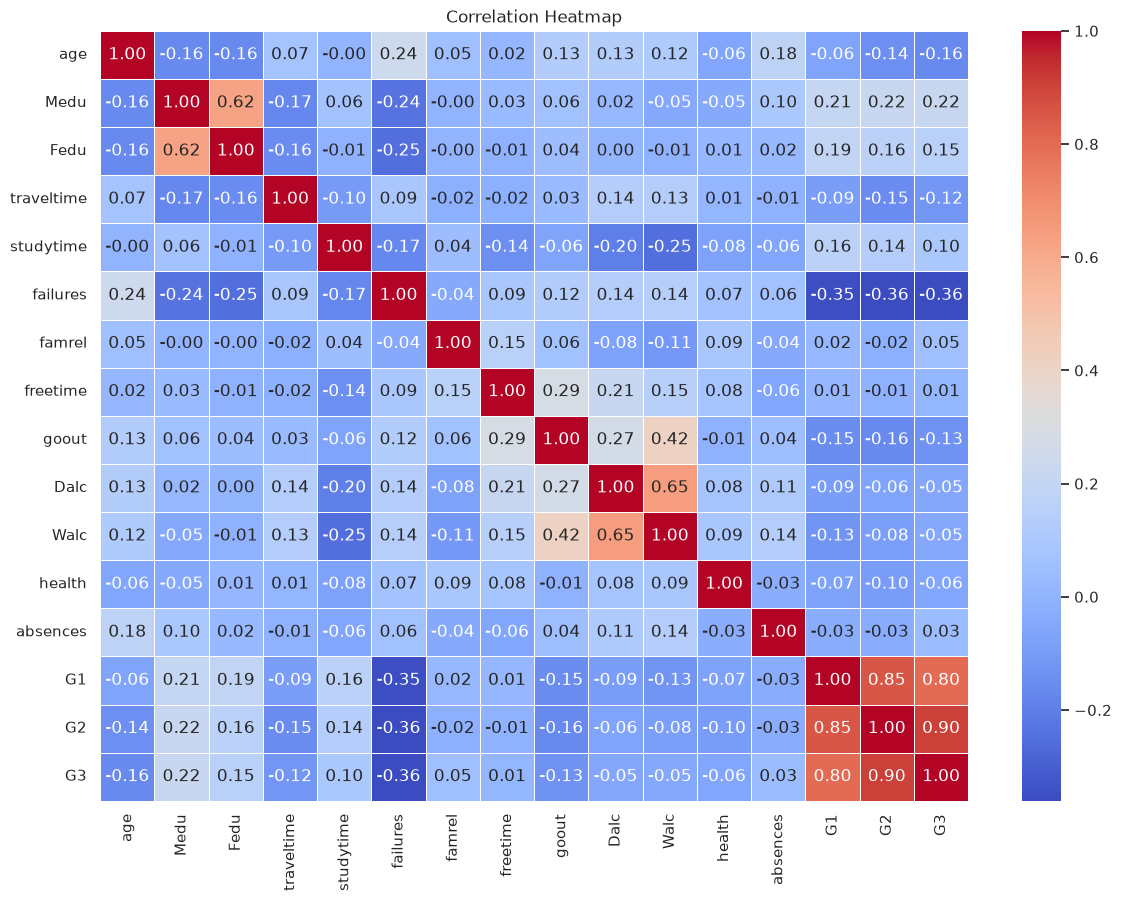

In [17]:
# Multivariate analysis — correlation heatmap

numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap")
plt.show()

# Close to + ---> Strong positive linear relationship
# Close to 0 ---> Weak or no linear relationship
# Close to -1 ---> Strong negative linear relationship


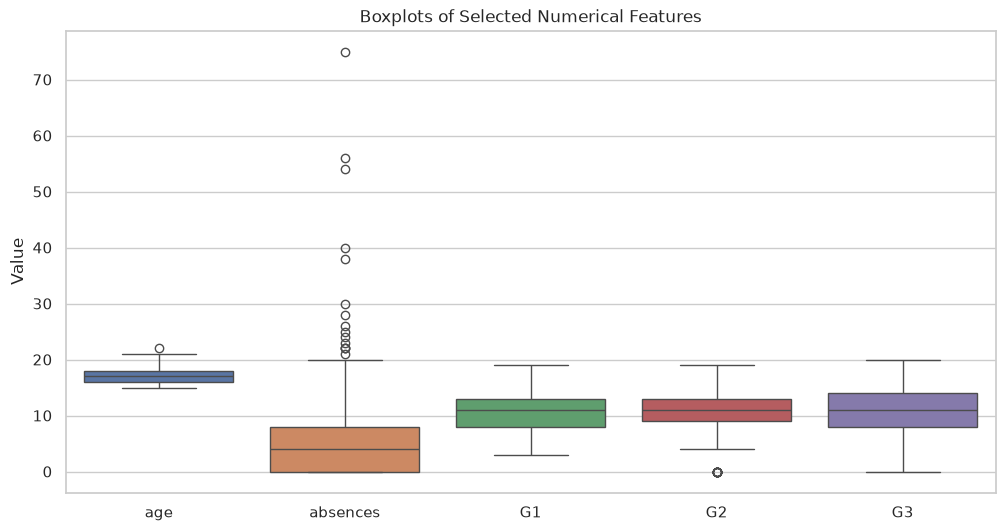

In [18]:
# checking outliers

plt.figure(figsize=(12, 6))

sns.boxplot(data=df[["age", "absences", "G1", "G2", "G3"]])

plt.title("Boxplots of Selected Numerical Features")
plt.ylabel("Value")
plt.show()

In [19]:
# Check the target variable

print("Final grade statistics:")
print(df["G3"].describe())

print("\nFinal grade frequencies:")
print(df["G3"].value_counts().sort_index())

Final grade statistics:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

Final grade frequencies:
G3
0     38
4      1
5      7
6     15
7      9
8     32
9     28
10    56
11    47
12    31
13    31
14    27
15    33
16    16
17     6
18    12
19     5
20     1
Name: count, dtype: int64


In [20]:
# identifying the strongest numerical correlations with the final grade, G3.

correlations = df.select_dtypes(include="number").corr()["G3"]
correlations = correlations.drop("G3").sort_values(
    ascending=False
)

print(correlations)

G2            0.904868
G1            0.801468
Medu          0.217147
Fedu          0.152457
studytime     0.097820
famrel        0.051363
absences      0.034247
freetime      0.011307
Walc         -0.051939
Dalc         -0.054660
health       -0.061335
traveltime   -0.117142
goout        -0.132791
age          -0.161579
failures     -0.360415
Name: G3, dtype: float64


In [21]:
# Reload and inspect the dataset

import pandas as pd
import numpy as np

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Dataset shape: (395, 33)
Missing values: 0
Duplicate rows: 0


In [22]:
# Separate features (X) and target (y)

X = df.drop(columns=["G3"])
y = df["G3"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (395, 32)
Target shape: (395,)


In [23]:
# Identifying numerical and categorical columns

categorical_cols = X.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X.select_dtypes(
    exclude=["object"]
).columns.tolist()

print("Categorical columns:")
print(categorical_cols)

print("\nNumerical columns:")
print(numerical_cols)

Categorical columns:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numerical columns:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


/tmp/ipykernel_5836/2333226125.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(


In [24]:
# Spliting the dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (316, 32)
Testing features: (79, 32)
Training targets: (316,)
Testing targets: (79,)


In [25]:
# Building the preprocessing pipeline

# OneHotEncoder for categorical columns.

# StandardScaler for numerical columns.

# ColumnTransformer to apply the correct transformation to each group.

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

numerical_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (316, 58)
Processed testing shape: (79, 58)


In [26]:
# Verify the preprocessing

print("Training rows:", X_train_processed.shape[0])
print("Testing rows:", X_test_processed.shape[0])

print("Training target rows:", len(y_train))
print("Testing target rows:", len(y_test))

print("Any missing values in original dataset:",
      df.isnull().sum().sum())

Training rows: 316
Testing rows: 79
Training target rows: 316
Testing target rows: 79
Any missing values in original dataset: 0


In [27]:
print("X_train exists:", "X_train" in globals())
print("X_test exists:", "X_test" in globals())
print("X_train_processed exists:", "X_train_processed" in globals())
print("preprocessor exists:", "preprocessor" in globals())

X_train exists: True
X_test exists: True
X_train_processed exists: True
preprocessor exists: True


In [28]:
# Model training

from sklearn.linear_model import LinearRegression

model = LinearRegression() # creates the model

model.fit(X_train_processed, y_train) # trains it using your preprocessed training data

# The model learns relationships between student features and final grades (G3)

print("Model training completed successfully!")

Model training completed successfully!


In [29]:
# Making predictions

y_pred = model.predict(X_test_processed)

print("Actual grades:")
print(y_test.head(10).tolist())

# This compares the actual final grades with the model's predictions for the first 10 test records

print("\nPredicted grades:")
print(*np.round(y_pred[:10], 2), sep=" , ")

Actual grades:
[10, 12, 5, 10, 9, 13, 18, 6, 0, 14]

Predicted grades:
6.0 , 11.53 , 2.87 , 8.8 , 8.55 , 11.89 , 19.1 , 7.17 , 7.41 , 12.31


In [30]:
# Evaluating the model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

# Average absolute difference between actual and predicted grades. Lower is better
print(f"MAE:  {mae:.2f}")

# Penalizes larger prediction errors more heavily. Lower is better
print(f"RMSE: {rmse:.2f}")

# Measures performance relative to predicting the mean grade. Closer to 1 is generally better
print(f"R²:   {r2:.3f}")

MAE:  1.65
RMSE: 2.38
R²:   0.724


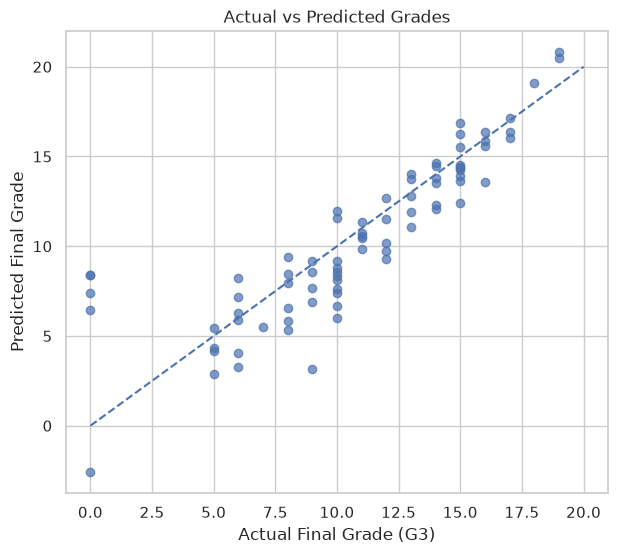

In [31]:
# Visualize actual vs predicted grades

import matplotlib.pyplot as plt

plt.figure(figsize=(7, 6))

plt.scatter(y_test, y_pred, alpha=0.7)

plt.plot(
    [0, 20],
    [0, 20],
    linestyle="--"
)

# Points closer to the dashed diagonal represent more accurate predictions

plt.xlabel("Actual Final Grade (G3)")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades")
plt.show()

In [32]:
# Comparing with Random Forest Regression
# Linear Regression assumes a linear relationship between the features and target. A Random Forest can learn more complex, nonlinear relationships

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    min_samples_leaf=2
)

rf_model.fit(X_train_processed, y_train)

rf_pred = rf_model.predict(X_test_processed)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest Results")
print(f"MAE:  {rf_mae:.2f}")
print(f"RMSE: {rf_rmse:.2f}")
print(f"R²:   {rf_r2:.3f}")

Random Forest Results
MAE:  1.21
RMSE: 2.04
R²:   0.797


In [33]:
comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]
})

comparison

,Model,MAE,RMSE,R2
0,Linear Regression,1.646666,2.378370,0.724134
1,Random Forest,1.211474,2.041505,0.796745


In [34]:
# Understanding feature importance

feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
14,num__G2,0.798769
12,num__absences,0.115475
36,cat__reason_home,0.018275
0,num__age,0.009684
13,num__G1,0.004680
40,cat__guardian_mother,0.003633
6,num__famrel,0.003553
11,num__health,0.003404
35,cat__reason_course,0.003289
8,num__goout,0.002692


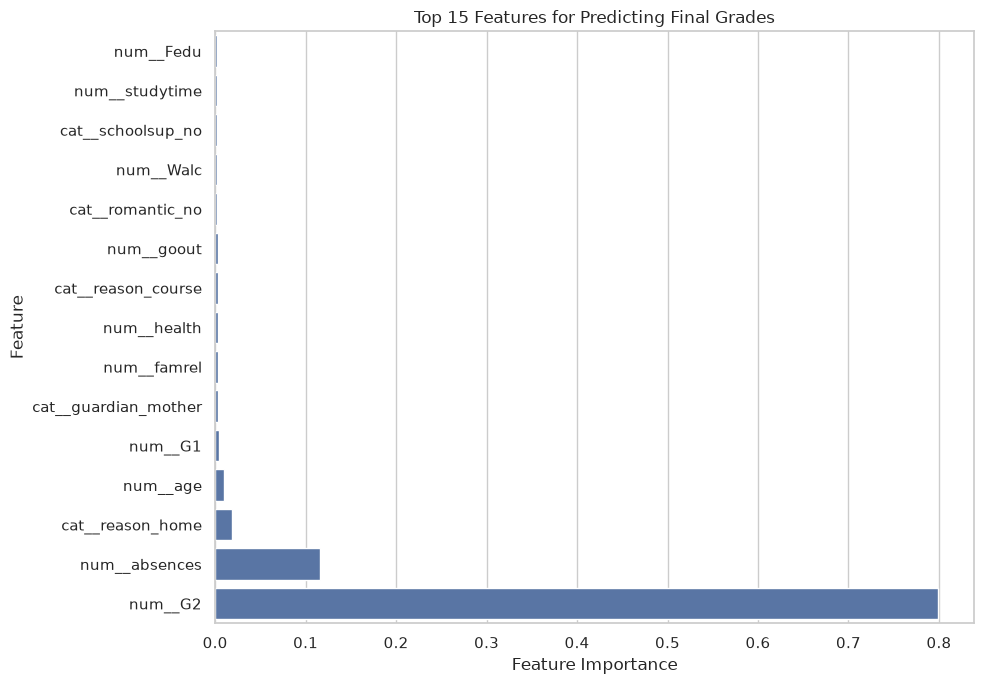

In [35]:
top_features = importance_df.head(15).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features for Predicting Final Grades")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [36]:
# Hyperparameter tuning with GridSearchCV
# improving Random Forest by testing different settings and selecting the best combination using cross-validation

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

param_grid = {
    "model__n_estimators": [100, 200], # number of trees in the forest
    "model__max_depth": [None, 5, 10], # maximum depth of each tree
    "model__min_samples_leaf": [1, 2, 4] # minimum number of training samples required in a leaf
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5, # splits the training data into five folds for validation
    scoring="neg_mean_absolute_error", # selects the model with the lowest MAE
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation MAE:")
print(-grid_search.best_score_)

Best parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 1, 'model__n_estimators': 100}

Best cross-validation MAE:
0.9015959877279078


In [37]:
# Evaluating the tuned model on test set

best_model = grid_search.best_estimator_

tuned_pred = best_model.predict(X_test)

tuned_mae = mean_absolute_error(y_test, tuned_pred)
tuned_rmse = np.sqrt(mean_squared_error(y_test, tuned_pred))
tuned_r2 = r2_score(y_test, tuned_pred)

print("Tuned Random Forest Results")
print(f"MAE:  {tuned_mae:.3f}")
print(f"RMSE: {tuned_rmse:.3f}")
print(f"R²:   {tuned_r2:.3f}")

Tuned Random Forest Results
MAE:  1.212
RMSE: 2.029
R²:   0.799


In [38]:
# Saving trained model

import joblib

joblib.dump(
    best_model,
    "student_performance_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [39]:
# Test loading the saved model

loaded_model = joblib.load(
    "student_performance_model.pkl"
)

loaded_predictions = loaded_model.predict(X_test)

print("First 10 predictions:")
print(*np.round(loaded_predictions[:10], 2), sep =" , ")

First 10 predictions:
8.21 , 11.68 , 6.51 , 9.8 , 8.61 , 12.8 , 18.78 , 6.77 , 7.05 , 13.26


In [40]:
print("best_model exists:", "best_model" in globals())
print("X_train exists:", "X_train" in globals())
print("y_train exists:", "y_train" in globals())

best_model exists: True
X_train exists: True
y_train exists: True


In [54]:
# Evaluating the tuned model using cross-validation

from sklearn.model_selection import KFold, cross_validate
import numpy as np

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2"
    },
    n_jobs=-1
)

mae_scores = -cv_results["test_mae"]
r2_scores = cv_results["test_r2"]

print("Cross-validation MAE scores:",
      np.round(mae_scores, 3))
print(f"Mean MAE: {mae_scores.mean():.3f}")
print(f"MAE standard deviation: {mae_scores.std():.3f}")

print("\nCross-validation R² scores:",
      np.round(r2_scores, 3))
print(f"Mean R²: {r2_scores.mean():.3f}")
print(f"R² standard deviation: {r2_scores.std():.3f}")

Cross-validation MAE scores: [0.829 1.26  0.821 0.778 1.067]
Mean MAE: 0.951
MAE standard deviation: 0.185

Cross-validation R² scores: [0.899 0.845 0.91  0.936 0.856]
Mean R²: 0.889
R² standard deviation: 0.034


In [55]:
import pandas as pd
import numpy as np
import joblib

from sklearn.model_selection import KFold, cross_validate

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded:", df.shape)

Dataset loaded: (395, 33)


In [56]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (316, 32)
Testing data: (79, 32)


In [57]:
best_model = joblib.load("student_performance_model.pkl")

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [58]:
import os

print("Current directory:", os.getcwd())
print(os.listdir())

Current directory: /home/skm/AI_ML/student-performance-prediction
['student.txt', '.ipynb_checkpoints', 'anaconda_projects', 'student-por.csv', 'Start.ipynb', '01_data_understanding.ipynb', 'student_performance_model.pkl', 'student-mat.csv', '.student.zip_old', '02_exploratory_data_analysis.ipynb', 'student.zip', 'student-merge.R', '.venv', '.virtual_documents', 'student-performance.zip']


In [59]:
#Error analysis

from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Predict on the held-out test set
test_pred = best_model.predict(X_test)

# Create an error analysis table
results = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": test_pred
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute Error"] = results["Error"].abs()

display(results.head(10))

print("Mean absolute error:",
      round(results["Absolute Error"].mean(), 3))

print("Largest absolute error:",
      round(results["Absolute Error"].max(), 3))

,Actual,Predicted,Error,Absolute Error
0,10,8.208750,1.791250,1.791250
1,12,11.681250,0.318750,0.318750
2,5,6.510000,-1.510000,1.510000
3,10,9.802949,0.197051,0.197051
4,9,8.611486,0.388514,0.388514
5,13,12.800000,0.200000,0.200000
6,18,18.780000,-0.780000,0.780000
7,6,6.770000,-0.770000,0.770000
8,0,7.052333,-7.052333,7.052333
9,14,13.263333,0.736667,0.736667


Mean absolute error: 1.212
Largest absolute error: 7.1


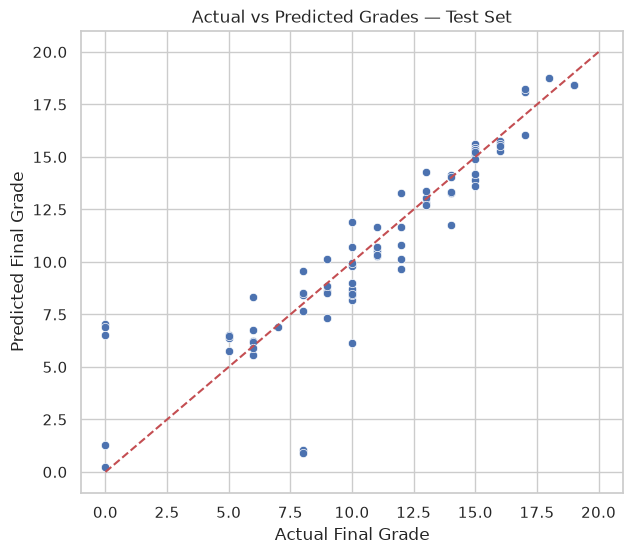

In [60]:
# Plot actual vs predicted grades

plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=results,
    x="Actual",
    y="Predicted"
)

plt.plot([0, 20], [0, 20], "r--")

plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Grades — Test Set")
plt.show()

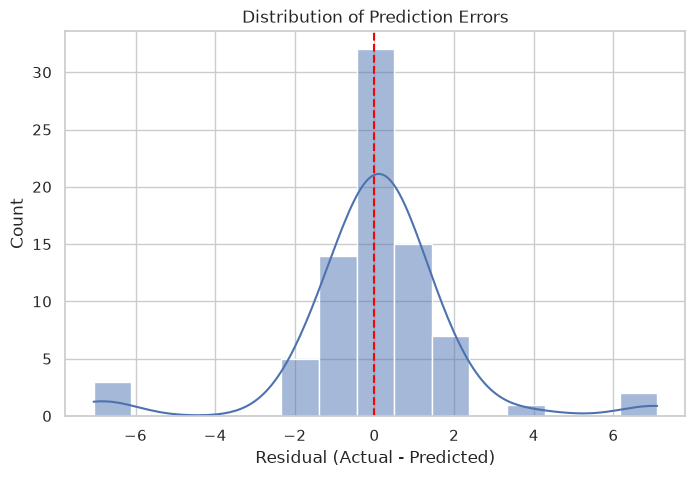

In [61]:
# Plot residuals

plt.figure(figsize=(8, 5))

sns.histplot(results["Error"], bins=15, kde=True)

plt.axvline(0, color="red", linestyle="--")

plt.xlabel("Residual (Actual - Predicted)")
plt.title("Distribution of Prediction Errors")
plt.show()

In [62]:
# Find the students with the largest prediction errors

# Add original student features to the error table

error_details = X_test.reset_index(drop=True).copy()

error_details["Actual_G3"] = y_test.to_numpy()
error_details["Predicted_G3"] = test_pred
error_details["Absolute_Error"] = (
    error_details["Actual_G3"] - error_details["Predicted_G3"]
).abs()

worst_predictions = error_details.sort_values(
    by="Absolute_Error",
    ascending=False
)

display(
    worst_predictions[
        ["G1", "G2", "absences", "Actual_G3",
         "Predicted_G3", "Absolute_Error"]
    ].head(10)
)

# This helps us investigate whether the model's largest errors are associated with unusual previous grades, absences, or other student characteristics.
# It won't establish the cause by itself.

,G1,G2,absences,Actual_G3,Predicted_G3,Absolute_Error
34,7,7,0,8,0.900000,7.100000
8,8,8,0,0,7.052333,7.052333
16,8,7,0,8,1.060000,6.940000
19,10,9,0,0,6.911470,6.911470
24,7,9,0,0,6.520000,6.520000
45,11,10,0,10,6.136479,3.863521
27,8,10,0,12,9.652600,2.347400
70,8,8,8,6,8.311464,2.311464
38,12,12,2,14,11.760000,2.240000
13,11,12,0,10,11.906250,1.906250


In [63]:
# Improve the model's reliability

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Exclude full-year absences for mid-year prediction
X_midyear = df.drop(columns=["G3", "absences"])
y_midyear = df["G3"]

X_train_mid, X_test_mid, y_train_mid, y_test_mid = train_test_split(
    X_midyear,
    y_midyear,
    test_size=0.20,
    random_state=42
)

categorical_mid = X_midyear.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_mid = X_midyear.select_dtypes(
    exclude=["object"]
).columns.tolist()

preprocessor_mid = ColumnTransformer([
    ("num", StandardScaler(), numerical_mid),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_mid)
])

pipeline_mid = Pipeline([
    ("preprocessor", preprocessor_mid),
    ("model", RandomForestRegressor(random_state=42))
])

param_grid_mid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

grid_mid = GridSearchCV(
    pipeline_mid,
    param_grid_mid,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring="neg_mean_absolute_error",
    n_jobs=-1
)

grid_mid.fit(X_train_mid, y_train_mid)

mid_model = grid_mid.best_estimator_
mid_pred = mid_model.predict(X_test_mid)

print("Best parameters:", grid_mid.best_params_)
print(f"MAE:  {mean_absolute_error(y_test_mid, mid_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_mid, mid_pred)):.3f}")
print(f"R²:   {r2_score(y_test_mid, mid_pred):.3f}")

/tmp/ipykernel_5836/2207232172.py:26: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_mid = X_midyear.select_dtypes(


Best parameters: {'model__max_depth': 5, 'model__min_samples_leaf': 4, 'model__n_estimators': 200}
MAE:  1.488
RMSE: 2.351
R²:   0.730


In [64]:
import joblib

best_model = joblib.load("student_performance_model.pkl")

print("Original tuned Random Forest loaded successfully!")

Original tuned Random Forest loaded successfully!


In [65]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_csv("student-mat.csv", sep=";")

X = df.drop(columns=["G3"])
y = df["G3"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Original dataset and test split restored.")

Original dataset and test split restored.


In [66]:
original_pred = best_model.predict(X_test)

print("Original Tuned Random Forest")
print(f"MAE:  {mean_absolute_error(y_test, original_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, original_pred)):.3f}")
print(f"R²:   {r2_score(y_test, original_pred):.3f}")

Original Tuned Random Forest
MAE:  1.212
RMSE: 2.029
R²:   0.799
